# Preprocessing

Le but de ce notebook est de travailler la donnée issue des verbatims pour pouvoir mener une analyse sémantique la plus riche possible.

Nous passerons donc :
- Par la création de colonnes qui regroupent certaines notes en catégories (3)
- Par l'identification de signaux dans les verbatims (points d'exclamations et mots écrits en lettre CAPITALES)
- Par le nettoyage des mots inutiles et de la ponctuation
- Par la lemmatisation, soit le regroupement des mots qui ont une même racine (ex : trouver, trouve --> 1 seul mot).

Dans un autre notebook, nous pourrons mener l'analyse sémantique (NLP), en essayant le BagOfWord, le TD-IDF, le N-series et ensuite le LDA pour regarder quelles mots / thématiques ressortent le plus par série et par niveau de satisfaction.

Par simplicité, nous ne garderons que les verbatims de Imdb, car en langue anglaise, et parce qu'il y en a nettement plus.

In [10]:
# Import des libraires

# Manipulation des données et visualisation
import pandas as pd, numpy as np, re, os
import seaborn as sns
import matplotlib.pyplot as plt

# Natural Language Processing (NLP)
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import WordNetLemmatizer
from afinn import Afinn
import string

In [11]:
# Import du dataframe
df = pd.read_csv("../0_Data/2_Clean/Traitement_intermediaire/data_clean.csv")

# Sélection du dataframe sur la plateforme IMDB pour simplifier le travail.
df = df[df["plateforme"] == 'Imdb']
df

,avis,dates,series,allocine_id,review_id,plateforme,notes
210,Honest Opinion - Turns out Westeros is way mor...,2026-01-24,A Knight of the Seven Kingdoms,28230,35604211,Imdb,8
211,"So Far, So Good (Don't Screw It Up) - The firs...",2026-01-19,A Knight of the Seven Kingdoms,28230,35604212,Imdb,9
212,A proper return to Westeros - I stayed up for ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604213,Imdb,9
213,The only disappointment i had with ep 1 - Its ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604214,Imdb,9
214,Really freaking good with only one bad moment ...,2026-01-19,A Knight of the Seven Kingdoms,28230,35604215,Imdb,9
...,...,...,...,...,...,...,...
1617,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,35604,35605618,Imdb,1
1618,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,35604,35605619,Imdb,3
1619,I get it... -,2026-02-26,King & Conqueror,35604,35605620,Imdb,7
1620,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,35604,35605621,Imdb,3


## 1. Ajout de colonnes

Enregistrement des informations les plus importantes : le regroupement de notes en 3 catégories, les métadonnées et le score de Sentiment.

In [12]:
# Création des fonctions pour créer des regroupements de la note (en 3 catégories)
def notes_3_cat(value):
    if value < 4:
        return -1
    elif 4 <= value < 7:
        return 0
    else:
        return 1

# Création des colonnes
df['notes_3'] = df['notes'].map(notes_3_cat)

In [13]:
# Vérification des effectifs de notes par série
for serie in df['series'].unique():
    print(f'Distribution des notes de la série {serie} : \n', df[df['series'] == serie]['notes_3'].value_counts())
    print()

# Des échantillons suffisants pour les catégories de notes des deux séries.

Distribution des notes de la série A Knight of the Seven Kingdoms : 
 notes_3
 1    1017
-1     127
 0      95
Name: count, dtype: int64

Distribution des notes de la série King & Conqueror : 
 notes_3
-1    81
 1    50
 0    42
Name: count, dtype: int64



In [14]:
# Création des fonctions
def capital_count(text : str):
    '''Compter le nombre de mots écrits en lettres capitales dans un texte'''
    capital = re.compile(r'[A-Z]{2,}')
    capital_search = capital.findall(text)
    return len(capital_search)

def exclamation_count(text : str):
    '''Compter le nombre de points d'exclamation dans un texte'''
    exclamation = re.compile(r'!')
    exclamation_search = exclamation.findall(text)
    return len(exclamation_search)

def exclamation_chain_count(text : str):
    '''Compter le nombre de chaînes de points d'exclamation (!!!) dans un texte'''
    exclamation_chain = re.compile(r'[!]{2,}')
    exclamation_chain_search = exclamation_chain.findall(text)
    return len(exclamation_chain_search)

def interrogation_count(text : str):
    '''Compter le nombre de points d'interrogation dans un texte'''
    interrogation = re.compile(r'\?')
    interrogation_search = interrogation.findall(text)
    return len(interrogation_search)

def interrogation_chain_count(text : str):
    '''Compter le nombre de chaînes de points d'exclamation (!!!) dans un texte'''
    interrogation_chain = re.compile(r'[?]{2,}')
    interrogation_chain_search = interrogation_chain.findall(text)
    return len(interrogation_chain_search)

# Création des colonnes de métadonnées
df['nb_capital_words'] = df['avis'].apply(capital_count)
df['nb_exclamation_points'] = df['avis'].apply(exclamation_count)
df['nb_exclamation_points_chains'] = df['avis'].apply(exclamation_chain_count)
df['nb_interrogation_points'] = df['avis'].apply(interrogation_count)
df['nb_interrogation_points_chains'] = df['avis'].apply(interrogation_chain_count)
df['lenght'] = df['avis'].apply(len)

In [15]:
df.describe()

,allocine_id,review_id,notes,notes_3,nb_capital_words,nb_exclamation_points,nb_exclamation_points_chains,nb_interrogation_points,nb_interrogation_points_chains,lenght
count,1412.000000,1.412000e+03,1412.000000,1412.000000,1412.000000,1412.000000,1412.000000,1412.000000,1412.000000,1412.000000
mean,29133.471671,3.560492e+07,7.956799,0.608357,0.952550,0.453258,0.051700,0.218130,0.012040,588.647309
std,2418.694309,4.077536e+02,3.010537,0.730242,3.374543,1.408669,0.270477,0.774695,0.132563,550.852360
min,28230.000000,3.560421e+07,1.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
25%,28230.000000,3.560456e+07,7.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,339.000000
50%,28230.000000,3.560492e+07,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,419.000000
75%,28230.000000,3.560527e+07,10.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,684.000000
max,35604.000000,3.560562e+07,10.000000,1.000000,67.000000,27.000000,3.000000,12.000000,2.000000,4995.000000


In [16]:
# Regardons directement les commentaires qui ont des métadonnées supérieures à 1.
# Nous traiterons le cas de 'length' différemment

df_metadonnees = df[['nb_capital_words', 'nb_exclamation_points', 'nb_exclamation_points_chains', \
                     'nb_interrogation_points', 'nb_interrogation_points_chains']]

for col in df_metadonnees:
    print(col, ' :')
    display(df[['avis', 'notes_3']][df_metadonnees[col] >= 1])
    print() # Saut de ligne

nb_capital_words  :


,avis,notes_3
211,"So Far, So Good (Don't Screw It Up) - The firs...",1
212,A proper return to Westeros - I stayed up for ...,1
214,Really freaking good with only one bad moment ...,1
217,Dunk is no lunk! - Wow! Just WOW! A Knight of ...,1
218,Short episodes but definitely enjoyable - Over...,1
...,...,...
1603,Utter nonsense - By all means make a drama set...,-1
1608,GOT fictional insult to English history - BBC ...,-1
1613,Well..... - I'm certain I'm writing a review m...,0
1614,Disapointment - I Had high hopes. It is such a...,-1



nb_exclamation_points  :


,avis,notes_3
213,The only disappointment i had with ep 1 - Its ...,1
217,Dunk is no lunk! - Wow! Just WOW! A Knight of ...,1
221,Great - I'm absolutely loving A Knight of the ...,1
223,"Epic, love this - Episode 2 is only 30 minutes...",1
228,"Great start! - Very good pilot, the cinematogr...",1
...,...,...
1601,Worse than bad!! - I cannot begin to try to ex...,-1
1604,Teenage drama trying to be serious... - Was Ha...,0
1610,Soap Opera Video Quality so I didn't even watc...,-1
1614,Disapointment - I Had high hopes. It is such a...,-1



nb_exclamation_points_chains  :


,avis,notes_3
309,Loved the Cinematography!!! - Absolute cinemat...,1
313,Best Casting! - Dunk & Egg's Casting is Amazin...,1
320,Series might just be a another GOT and i bet i...,1
404,HBO/Martin's next strike!!! - Having seen the ...,1
441,LOVEEED - Love love love (Mister finn bennett ...,1
449,Almost perfect - I like that the series doesn'...,1
458,Dunk and Egg!!!! - What a fantastic series til...,1
472,"Finally, Someone to Root For!! - A Knight of t...",1
485,Out Freakin Standing!!! - This has the potenti...,1
531,Surprising! - Not one to leave reviews but I w...,1



nb_interrogation_points  :


,avis,notes_3
213,The only disappointment i had with ep 1 - Its ...,1
226,Landmark TV - Episode 1 Jan 19. 2026\n\nSimple...,1
230,2 good episodes out of 6 - With such rich Iris...,0
232,"Fantasy From the Road, Not the Throne - This r...",1
233,A small and perfect GOT story - From the momen...,1
...,...,...
1604,Teenage drama trying to be serious... - Was Ha...,0
1610,Soap Opera Video Quality so I didn't even watc...,-1
1611,Why the mini horses? - I had trouble taking th...,0
1617,Mediocre filmmaking - Weak script in combinati...,-1



nb_interrogation_points_chains  :


,avis,notes_3
298,Why only 40 mins and one episode??? - The firs...,1
363,"Very boring snoozefest, perhaps suitable for 8...",-1
371,"Terrible start, but improving - I was looking ...",1
446,Got level goated ?? - Episode 1 begins on a ve...,1
475,FREAKING AWESOME! - Unlike all the other dummi...,1
584,Charming but not Game of Thrones - It's defini...,0
741,Boooooring - What is up with those reviews??? ...,-1
864,I see emmy sphree - Perfect casting...good act...,1
946,Very good GoT prequel but short episodes/seaso...,1
1132,10/10!!!!! - Well what can one say??? I guess ...,1


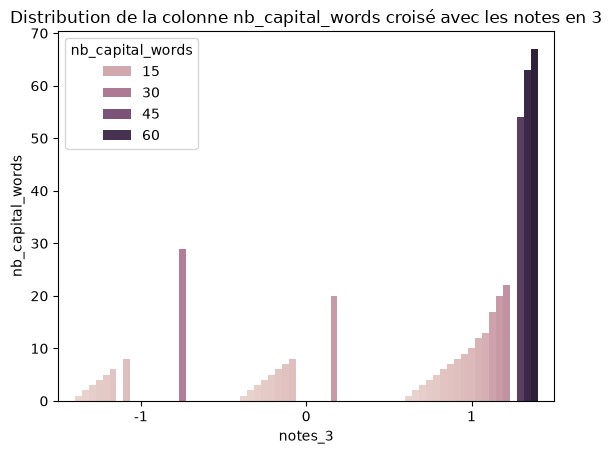

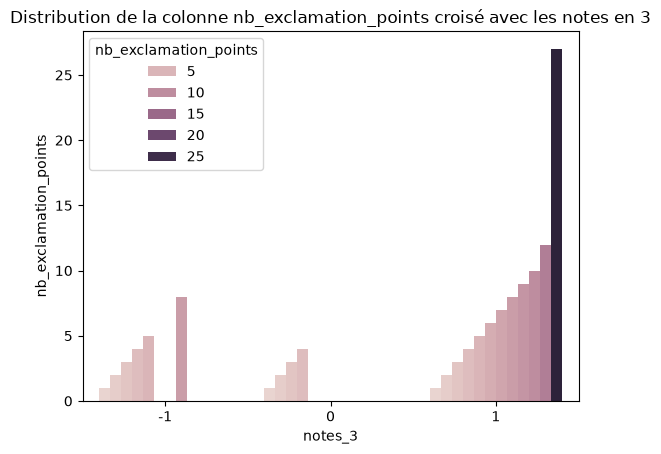

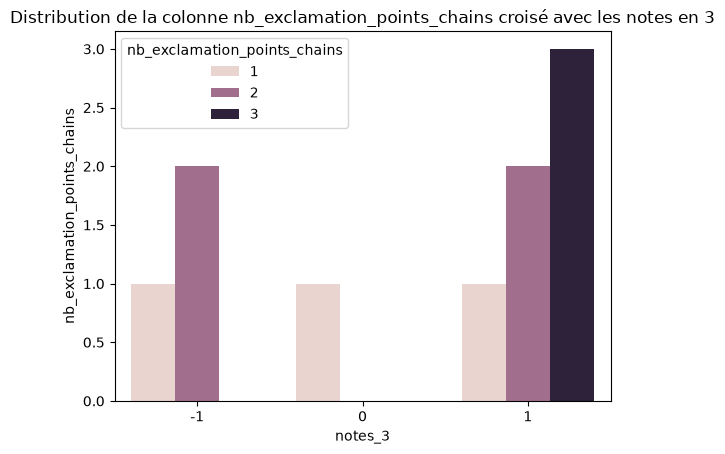

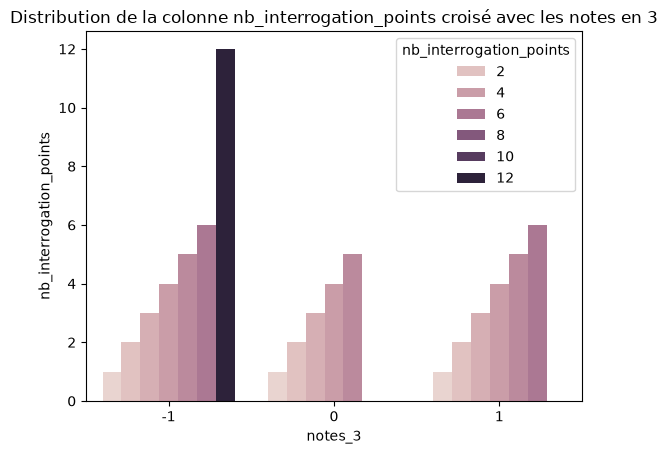

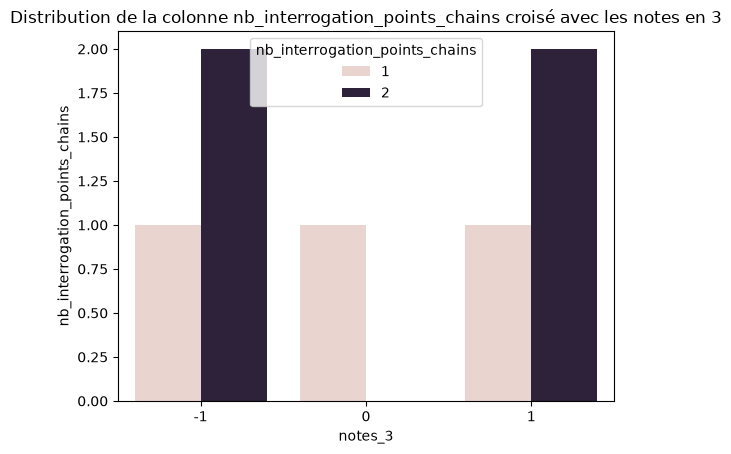

In [17]:
# Analysons l'impact des métadonnées lorsqu'elle sont au moins égales à 1
for col in df_metadonnees:
    sns.barplot(data=df[df[col] >=1], x='notes_3', \
                y=col, hue=col)
    plt.title(f'Distribution de la colonne {col} croisé avec les notes en 3')
    plt.show()

Enseignements :
- La présence de mots en lettre capitale semble corrélé positivement avec les notes positives. Surtout lorsqu'il y en a au moins 50 dans un même avis.
- Les points d'exclamation intensifient les avis : on les trouve davantage où il y a des notes positives et négatives. Lorsqu'il y en a plus de 15, c'est un signe que la note est positive.
- A l'inverse, les points d'interrogration semblent davantage présent pour mettre en cause la série, surtout lorsqu'il y en a beaucoup (10 ou plus)

## 2. Nettoyage

Dans cette section, nous allons retirer les mots inutiles et la ponctuation.

In [18]:
# Si ces fichiers ne sont pas téléchargés, retirer les #, puis les remettre.
# nltk.download('stopwords')
# nltk.download('punkt')
# nltk.download('punkt_tab')

# Text test
text = "This is a sample sentence showing stopword removal."

# Fonction pour retirer les mots inutiles en anglais
def preprocess_verbatim(verbatim):
    '''Tokenize les mots de chaque verbatim en retirant les mots inutiles et la ponctuation'''
    
    stop_words = set(stopwords.words('english')) # Liste des mots inutiles à retirer.

    verbatim = verbatim.lower()             # Tous les mots en minuscule
    tokenizer = RegexpTokenizer(r'\w+')     # Fonction de tokenisation en retirant la ponctuation.
    tokens = tokenizer.tokenize(verbatim)   # Tokenisation

    filtered_words = [word for word in tokens if word not in stop_words]    # Filtrage des mots inutiles
    return " ".join(filtered_words) # 

# Création de la colonne avec les tokens.
df['tokens'] = df['avis'].apply(preprocess_verbatim)
df['tokens']


210     honest opinion turns westeros way interesting ...
211     far good screw first episode knight seven king...
212     proper return westeros stayed 3 uk premiere on...
213     disappointment ep 1 42 minuts expected hour ho...
214     really freaking good one bad moment far knight...
                              ...                        
1617    mediocre filmmaking weak script combination we...
1618    drunk history many reviewers noted events noth...
1619                                                  get
1620    realism earl military crews count 5 8 soldiers...
1621    historical inaccuracies historical inaccuracie...
Name: tokens, Length: 1412, dtype: str

## 3. Lemmatisation

Nous ferons de la lemmatisation pour conserver la racine de chaque mot, que ce soit un verbe ou un nom.

Dans un prochain notebook, nous pourrons nous concentrer sur le coeur de l'analyse sémantique. nous testerons différentes techniques de tokenisation pour déceler les catégories qui ressortent le plus.

In [19]:
# Si ces fichiers ne sont pas téléchargés, retirer les #, puis les remettre.
# nltk.download('wordnet')

# Initialisation du lemmatiseur
wordnet_lemmatizer = WordNetLemmatizer()

def lemmatisation(text):
    
    words = re.findall(r'\w+', text) # Liste des mots (sinon itère sur les lettres...)
    lemmatized = [wordnet_lemmatizer.lemmatize(word) for word in words]
    return " ".join(lemmatized)

df['tokens_lemmatized'] = df['tokens'].apply(lemmatisation)

# Peut l'intégrer à la fonction précédente.


In [20]:
# Vérification
test_words = re.findall(r'\w+', df['tokens'].iloc[0])
for w in test_words:
    print(f"{w} → {wordnet_lemmatizer.lemmatize(w)}")

# On voit à 'dragon' que la lemmatisation a fonctionnée. 

honest → honest
opinion → opinion
turns → turn
westeros → westeros
way → way
interesting → interesting
exploding → exploding
every → every
five → five
minutes → minute
dragons → dragon
throne → throne
drama → drama
one → one
well → well
meaning → meaning
idiot → idiot
sword → sword
kid → kid
clearly → clearly
smarter → smarter
everyone → everyone
else → else
slower → slower
quieter → quieter
somehow → somehow
heart → heart
epic → epic
fantasy → fantasy
like → like
honor → honor
bad → bad
decisions → decision
consequences → consequence
actually → actually
matter → matter
one → one
delivers → delivers
surprisingly → surprisingly
wholesome → wholesome


In [21]:
# Export en csv
# Un point = dossier actuel, deux points = dossier parent
output_path = '../0_Data/2_Clean/Traitement_intermediaire/data_preprocessed.csv'
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df.to_csv(output_path, index=False)